## Практическое задание №3

В файле **WIPO-GII_2022.xlsx** содержаться данные по странам о показателях, используемых для расчета Global Innovation Index за 2022 год. 

### В файле следующие переменные:																																
- Country
- Business environment
- Business sophistication index
- Citable documents H-index
- Creative goods and services
- Creative goods exports, % total trade
- Creative outputs index
- Cultural and creative services exports, % total trade
- Domestic market scale, bn PPP
- Ecological sustainability
- Expenditure on education, % GDP
- Firms offering formal training, %
- General infrastructure
- Government effectiveness
- Government's online service
- Graduates in science and engineering, %
- Gross expenditure on R&D, % GDP
- High-tech exports, % total trade
- High-tech imports, % total trade
- High-tech manufacturing, %
- Human capital and research index
- Information and Communications Technology access
- Information and Communications Technology services exports, % total trade
- Information and Communications Technology services imports, % total trade
- Information and Communications Technology use
- Infrastructure index
- Intangible assets
- Joint venture/strategic alliance deals/bn PPP GDP
- Knowledge absorption
- Knowledge and technology outputs index
- Knowledge workers
- Knowledge-intensive employment, %
- Logistics performance
- Market sophistication index
- Mobile app creation/bn PPP GDP
- Online creativity
- PISA scales in reading, maths and science
- Political and operational stability
- Political environment
- Pupil-teacher ratio, secondary
- QS university ranking average score of top 3 universities
- Research and development (R&D)
- Scientific and technical articles/bn PPP GDP
- Software spending, % GDP
- Tertiary education
- Tertiary enrolment, % gross
- University-industry R&D collaboration
- Region
- Region2
- Euro area
- European Union
- OECD members
- Least developed countries
- Income
- High income

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import calinski_harabasz_score, silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

df1 = pd.read_excel('WIPO-GII_2022.xlsx')

Выполните, пожалуйста, задания.

**1. Построение признакового пространства и снижение размерности для кластеризации**

- Выберите не менее 10 числовых признаков из датасета, которые потенциально подходят для построения модели кластеризации. Обоснуйте их выбор (информативность, вариативность, отсутствие пропусков, предметный смысл).

- Проведите корреляционный анализ выбранных признаков. Сделайте вывод о наличии или отсутствии мультиколлинеарности.

- При наличии значимых корреляций выполните снижение размерности данных. Используйте метод главных компонент (PCA). Возможно, что имеет смысл выделить компоненты не на основе всех рассматриваемых признаков, а только на части изначально отобранных. Определите оптимальное количество компонент. Для каждой выделенной компоненты укажите процент объяснённой вариации; проанализируйте нагрузки; дайте компоненте осмысленное название и обоснуйте его.

- Сохраните полученные компоненты в датасете в виде новых переменных и используйте их для дальнейшей кластеризации.

- Сформируйте финальный список признаков по которым будет проведена кластеризация. Это могут быть только исходные признаки; только сформированные компоненты или же комбинация из исходных признаков и компонентов. Приведите аргументы в пользу того, что финальный список признаков может быть использован для кластеризации объектов наблюдения.

**!Если не удается выделить компоненты на имеющихся данных, то приведите расчеты и аргументы, подтверждающие это.**

In [2]:
numeric_features = df1.select_dtypes(include='number').filter(regex='_2022$').columns.tolist()
display(pd.Series(numeric_features, name='Количественные показатели').to_frame())

,Количественные показатели
0,Business environment_2022
1,Business sophistication index_2022
2,Citable documents H-index_2022
3,Creative goods and services_2022
4,"Creative goods exports, % total trade_2022"
5,Creative outputs index_2022
6,"Cultural and creative services exports, % tota..."
7,"Domestic market scale, bn PPP$_2022"
8,Ecological sustainability_2022
9,"Expenditure on education, % GDP_2022"


**Выбор 10 числовых признаков**

Для кластеризации выбраны показатели, характеризующие условия для инноваций, подготовку кадров, научную деятельность и использование технологий. Для анализа я рассматриваю только показатели за 2022 год.

| Признак | Что показывает |
| --- | --- |
| Government effectiveness | Характеризует эффективность государственного управления и институциональные условия для развития науки и бизнеса. |
| General infrastructure | Отражает инфраструктурные условия, необходимые для деятельности предприятий и внедрения технологий. |
| Information and Communications Technology access | Показывает доступность инфраструктуры, важной для распространения знаний и технологий. |
| Expenditure on education, % GDP | Характеризует финансирование образования. |
| Graduates in science and engineering, % | Отражает количество новых кадров для исследований. |
| Gross expenditure on R&D, % GDP | Характеризует вложения в исследования и разработки. |
| Scientific and technical articles/bn PPP$ GDP | Отражает результативность научной деятельности с учётом масштаба экономики. |
| Knowledge-intensive employment, % | Характеризует распространённость вакансий, требующей высокой квалификации и знаний. |
| High-tech manufacturing, % | Показывает роль высокотехнологичного производства в экономике. |
| High-tech exports, % total trade | Характеризует участие страны в международной торговле высокотехнологичными продуктами. |


На следующем шаге проверим корреляции между выбранными признаками, чтобы выяснить, насколько они дублируют информацию друг друга и нужно ли снижать размерность данных.

In [3]:
features = [
    'Government effectiveness_2022',
    'General infrastructure_2022',
    'Information and Communications Technology access_2022',
    'Expenditure on education, % GDP_2022',
    'Graduates in science and engineering, %_2022',
    'Gross expenditure on R&D, % GDP_2022',
    'Scientific and technical articles/bn PPP$ GDP_2022',
    'Knowledge-intensive employment, %_2022',
    'High-tech manufacturing, %_2022',
    'High-tech exports, % total trade_2022',
]

X = df1[features].dropna()


feature_stats = pd.DataFrame({
    'count': X.count(),
    'nunique': X.nunique(),
    'min': X.min(),
    'max': X.max(),
    'std': X.std()
})
feature_stats['missing_before'] = df1[features].isna().sum()
display(feature_stats.round(2))
print(f'Рабочая выборка: {X.shape[0]} стран, {X.shape[1]} признаков.')
print(f'Исключено стран с пропусками: {len(df1) - len(X)} из {len(df1)}.')

,count,nunique,min,max,std,missing_before
Government effectiveness_2022,132,124,0.0,100.0,19.79,7
General infrastructure_2022,132,113,2.9,76.2,15.48,7
Information and Communications Technology access_2022,132,109,0.0,99.6,17.47,7
"Expenditure on education, % GDP_2022",132,114,0.0,100.0,18.98,7
"Graduates in science and engineering, %_2022",132,98,0.0,100.0,28.09,7
"Gross expenditure on R&D, % GDP_2022",132,99,0.0,100.0,19.49,7
Scientific and technical articles/bn PPP$ GDP_2022,132,121,0.0,100.0,23.70,7
"Knowledge-intensive employment, %_2022",132,117,0.0,100.0,25.83,7
"High-tech manufacturing, %_2022",132,102,0.0,100.0,25.19,7
"High-tech exports, % total trade_2022",132,115,0.0,100.0,25.98,7


Рабочая выборка: 132 стран, 10 признаков.
Исключено стран с пропусками: 7 из 139.


**Вывод по отбору признаков.**<br>
В исходном файле 139 стран. Для 7 стран отсутствуют все 46 количественных показателей за 2022 год, поэтому эти строки исключены. В результате для каждого из 10 выбранных признаков имеется 132 страны без пропусков, чего достаточно для анализа.

Признаки обладают вариативны, то есть число уникальных значений составляет от 98 до 124, стандартное отклонение от 15,48 до 28,09. Таким образом, среди них нет постоянных показателей, которые не позволяют различать страны.
Выбранные признаки охватывают несколько содержательных сторон технического развития.

**Корреляционный анализ**<br>

Для начала рассчитаем коэффициенты корреляции Пирсона и построим тепловую карту. Для удобства на графиках и в таблицах используем сокращённые русские названия.

Условно будем считать сильными связи с $|r|>= 0,7$. Статистическую значимость корреляций проверим с помощью Пирсона, сравним исходные p-значения с 0,05. 
Если p-значение меньше 0,05, будем считать линейную связь статистически значимой. 

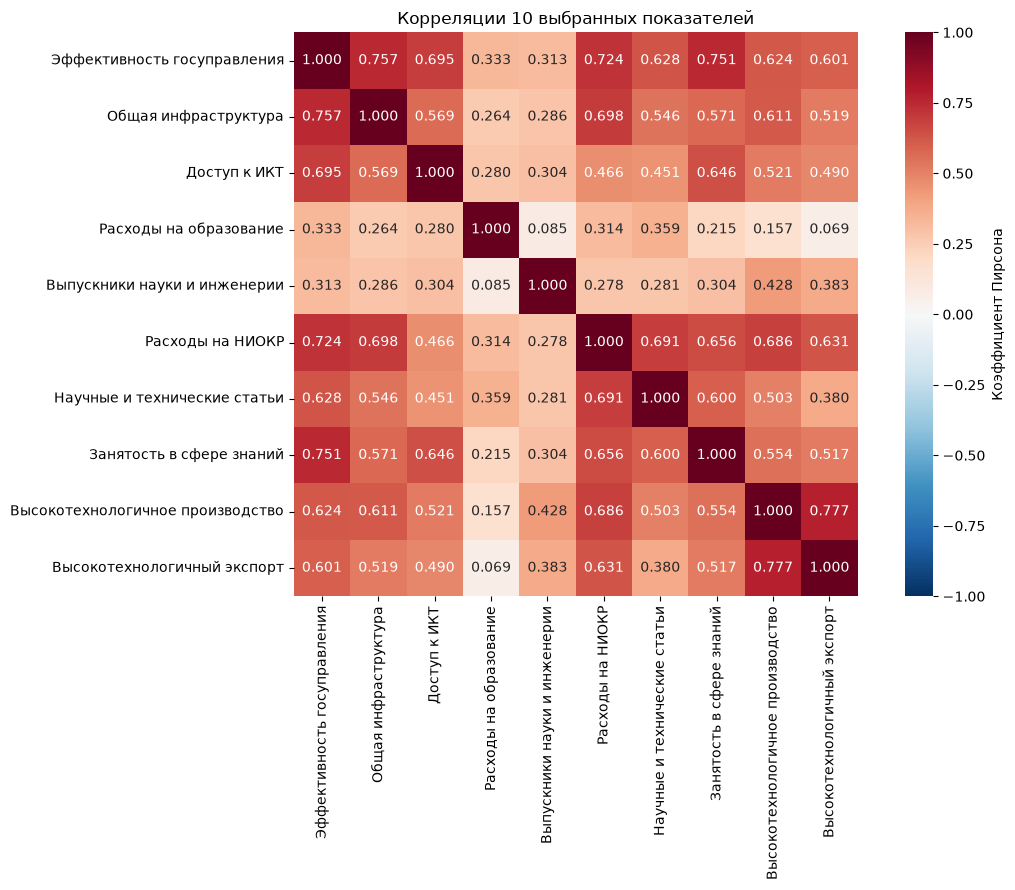

,Признак 1,Признак 2,r,p_value,Значима (p < 0.05)
0,Высокотехнологичное производство,Высокотехнологичный экспорт,0.776834,6.910342e-28,True
1,Эффективность госуправления,Общая инфраструктура,0.757320,8.035093e-26,True
2,Эффективность госуправления,Занятость в сфере знаний,0.750890,3.493769e-25,True
3,Эффективность госуправления,Расходы на НИОКР,0.724153,1.005068e-22,True


Сильных связей: 4 из 45 пар.


In [5]:
from scipy.stats import pearsonr

feature_names = dict(zip(features, [
    'Эффективность госуправления',
    'Общая инфраструктура',
    'Доступ к ИКТ',
    'Расходы на образование',
    'Выпускники науки и инженерии',
    'Расходы на НИОКР',
    'Научные и технические статьи',
    'Занятость в сфере знаний',
    'Высокотехнологичное производство',
    'Высокотехнологичный экспорт',
]))

corr_matrix = X.corr(method='pearson')
#display(corr_matrix.rename(index=feature_names, columns=feature_names).round(3))

plt.figure(figsize=(12, 9))
sns.heatmap(
    corr_matrix.rename(index=feature_names, columns=feature_names),
    annot=True, fmt='.3f', cmap='RdBu_r', vmin=-1, vmax=1,
    square=True, cbar_kws={'label': 'Коэффициент Пирсона'},
)

plt.title('Корреляции 10 выбранных показателей')
plt.tight_layout()
plt.show()

pairs = []
for i, first in enumerate(features):
    for second in features[i + 1:]:
        r, p_value = pearsonr(X[first], X[second])
        pairs.append({
            'Признак 1': feature_names[first],
            'Признак 2': feature_names[second],
            'r': r,
            'p_value': p_value,
        })

correlation_pairs = pd.DataFrame(pairs)
correlation_pairs['Значима (p < 0.05)'] = correlation_pairs['p_value'] < 0.05

strong_pairs = correlation_pairs.loc[
    correlation_pairs['r'].abs() >= 0.7
].sort_values('r', ascending=False)

display(strong_pairs.reset_index(drop=True))
print(f'Сильных связей: {len(strong_pairs)} из {len(correlation_pairs)} пар.')

**Вывод по корреляциям.**<br>
Найдены 4 сильные положительные связи:

- высокотехнологичное производство и высокотехнологичный экспорт: r = 0,78;
- эффективность госуправления и общая инфраструктура: r = 0,76;
- эффективность госуправления и занятость в сфере знаний: r = 0,75;
- эффективность госуправления и расходы на НИОКР: r = 0,72.

Все четыре сильные связи статистически значимы, так как исходные p-значения теста Пирсона меньше 0,05. Таким образом, некоторые выбранные признаки сильно коррелируют между собой и частично дублируют информацию.

Поэтому применим PCA ко всем 10 признакам. Так мы сможем сократить размерность данных, не исключая отдельные показатели вручную.

**Стандартизация и выбор числа главных компонент**

Перед PCA проведём z-стандартизацию: вычтем среднее и разделим на стандартное отклонение. Хотя все показатели находятся в пределах 0–100, их разброс различается, поэтому без стандартизации признаки с большей дисперсией получили бы больший вес.

В семинаре PCA рассчитывается через `FactorAnalyzer(method='principal')`. Здесь используем уже импортированный `sklearn.decomposition.PCA` без вращения осей. Как и в семинаре, рассмотрим график собственных значений и критерий Кайзера: оставляем компоненты с собственным значением корреляционной матрицы больше 1. Дополнительно проверим накопленную долю объяснённой вариации.

,Собственное значение,"Объяснённая вариация, %","Накопленная вариация, %"
PC1,5.535,55.345,55.345
PC2,1.121,11.209,66.554
PC3,0.801,8.011,74.565
PC4,0.662,6.616,81.180
PC5,0.579,5.794,86.974
PC6,0.433,4.333,91.307
PC7,0.311,3.112,94.419
PC8,0.218,2.176,96.595
PC9,0.187,1.866,98.461
PC10,0.154,1.539,100.000


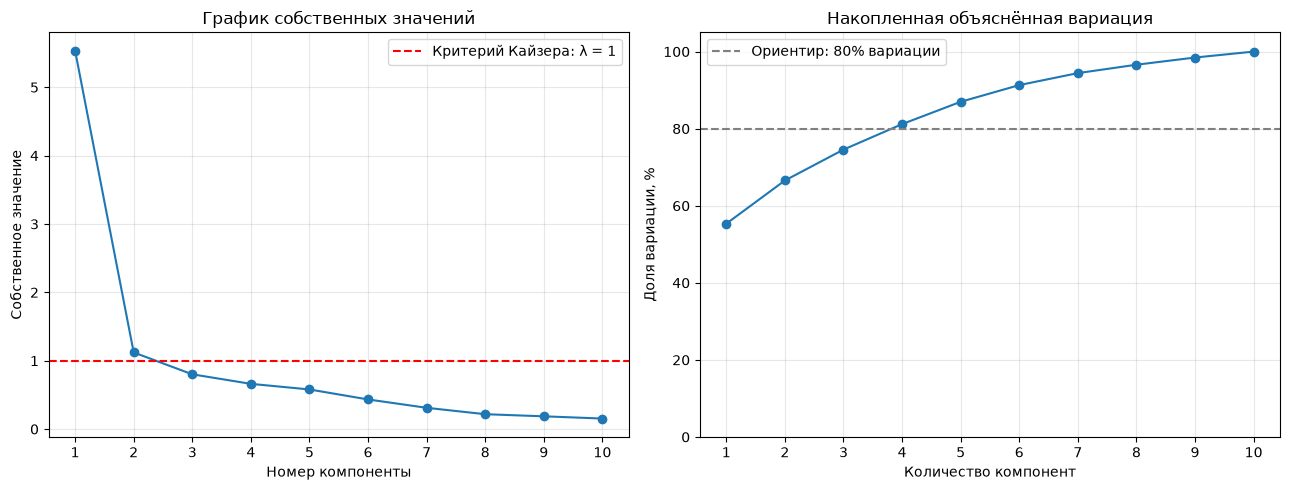

По критерию Кайзера: 2 компоненты.
Они объясняют 66.55% вариации.
Для сохранения не менее 80% потребовалось бы 4 компоненты.


In [5]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X), index=X.index, columns=features,
)

pca_full = PCA(svd_solver='full')
pca_full.fit(X_scaled)

# PCA использует дисперсию с ddof=1, а StandardScaler — с ddof=0.
# Приводим собственные значения к шкале корреляционной матрицы.
eigenvalues = pca_full.explained_variance_ * (len(X) - 1) / len(X)
variance_share = pca_full.explained_variance_ratio_
cumulative_share = np.cumsum(variance_share)

pca_diagnostics = pd.DataFrame({
    'Собственное значение': eigenvalues,
    'Объяснённая вариация, %': variance_share * 100,
    'Накопленная вариация, %': cumulative_share * 100,
}, index=[f'PC{i + 1}' for i in range(len(features))])
display(pca_diagnostics.round(3))

component_numbers = np.arange(1, len(features) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(component_numbers, eigenvalues, marker='o')
axes[0].axhline(1, color='red', linestyle='--', label='Критерий Кайзера: λ = 1')
axes[0].set(title='График собственных значений',
            xlabel='Номер компоненты', ylabel='Собственное значение')
axes[0].legend()
axes[1].plot(component_numbers, cumulative_share * 100, marker='o')
axes[1].axhline(80, color='gray', linestyle='--', label='Ориентир: 80% вариации')
axes[1].set(title='Накопленная объяснённая вариация',
            xlabel='Количество компонент', ylabel='Доля вариации, %', ylim=(0, 105))
axes[1].legend()
for ax in axes:
    ax.set_xticks(component_numbers)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

n_components = int((eigenvalues > 1).sum())
n_components_80 = int(np.searchsorted(cumulative_share, 0.8) + 1)
print(f'По критерию Кайзера: {n_components} компоненты.')
print(f'Они объясняют {cumulative_share[n_components - 1]:.2%} вариации.')
print(f'Для сохранения не менее 80% потребовалось бы {n_components_80} компоненты.')

**Выбор числа компонент.** Собственные значения первых двух компонент равны 5,535 и 1,121; у третьей — 0,801, далее они ещё меньше. По критерию Кайзера оставляем **2 компоненты**. На графике особенно заметно доминирование первой компоненты; отдельного столь же резкого излома после второй нет, поэтому решение не обосновывается только формой графика.

Первая компонента объясняет **55,35%**, вторая — **11,21%**, вместе — **66,55%** вариации (сумма округлённых долей может отличаться на 0,01 п.п.). Выбираем это решение как компактное представление общей структуры данных: размерность сокращается с 10 до 2, обе компоненты объясняют больше вариации, чем один стандартизированный исходный признак, и допускают содержательную интерпретацию.

Это компромисс: **33,45% вариации теряется**. Для сохранения не менее 80% пришлось бы оставить 4 компоненты — они объясняют 81,18%. Порог 80% не является обязательным правилом; в этой работе придерживаемся критерия Кайзера, как в семинаре. Такое решение подходит для укрупнённой сегментации, но может скрывать различия стран по отдельным показателям; при дальнейшей кластеризации это ограничение нужно учитывать. Выбор двух компонент не гарантирует лучшую кластеризацию по всем возможным критериям.

,PC1,PC2
Эффективность госуправления,0.894,0.113
Общая инфраструктура,0.812,0.064
Доступ к ИКТ,0.745,0.063
Расходы на образование,0.364,0.739
Выпускники науки и инженерии,0.463,-0.426
Расходы на НИОКР,0.857,0.068
Научные и технические статьи,0.744,0.281
Занятость в сфере знаний,0.812,0.052
Высокотехнологичное производство,0.814,-0.321
Высокотехнологичный экспорт,0.750,-0.428


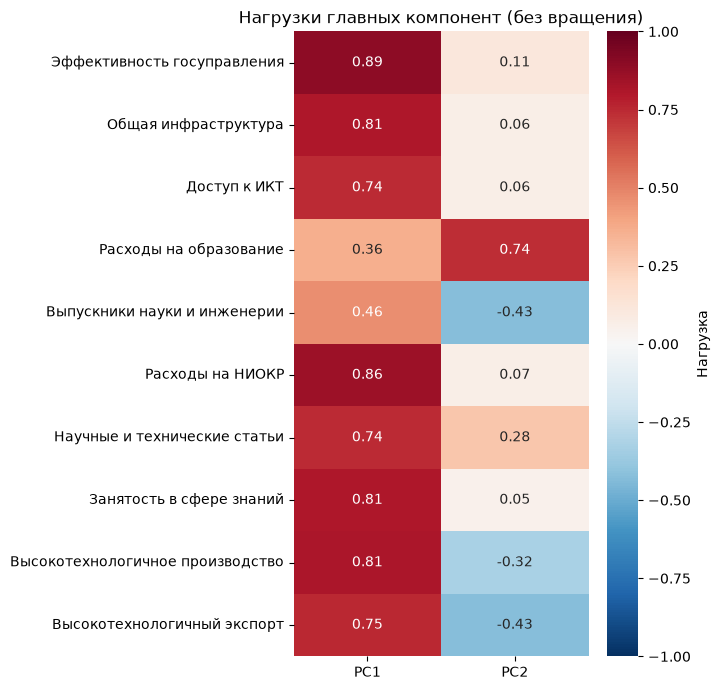


PC1: нагрузки по убыванию модуля


,PC1
Эффективность госуправления,0.894
Расходы на НИОКР,0.857
Высокотехнологичное производство,0.814
Общая инфраструктура,0.812
Занятость в сфере знаний,0.812
Высокотехнологичный экспорт,0.750
Доступ к ИКТ,0.745
Научные и технические статьи,0.744
Выпускники науки и инженерии,0.463
Расходы на образование,0.364



PC2: нагрузки по убыванию модуля


,PC2
Расходы на образование,0.739
Высокотехнологичный экспорт,-0.428
Выпускники науки и инженерии,-0.426
Высокотехнологичное производство,-0.321
Научные и технические статьи,0.281
Эффективность госуправления,0.113
Расходы на НИОКР,0.068
Общая инфраструктура,0.064
Доступ к ИКТ,0.063
Занятость в сфере знаний,0.052


In [6]:
pca = PCA(n_components=n_components, svd_solver='full')
component_values = pca.fit_transform(X_scaled)
component_columns = [f'PC{i + 1}' for i in range(n_components)]

# Фиксируем направление: наибольшая по модулю нагрузка положительна.
# Знак оси произволен и не влияет на расстояния между странами.
largest_weights = np.abs(pca.components_).argmax(axis=1)
signs = np.sign(pca.components_[np.arange(n_components), largest_weights])
pca.components_ *= signs[:, None]
component_values *= signs

components = pd.DataFrame(
    component_values, index=X.index, columns=component_columns,
)

# Нагрузки — корреляции исходных показателей с компонентами,
# а не просто коэффициенты собственных векторов pca.components_.
loadings = pd.DataFrame(
    pca.components_.T * np.sqrt(eigenvalues[:n_components]),
    index=[feature_names[name] for name in features],
    columns=component_columns,
)
display(loadings.round(3))

plt.figure(figsize=(7, 7))
sns.heatmap(loadings, annot=True, fmt='.2f', cmap='RdBu_r',
            vmin=-1, vmax=1, cbar_kws={'label': 'Нагрузка'})
plt.title('Нагрузки главных компонент (без вращения)')
plt.tight_layout()
plt.show()

for column in component_columns:
    print(f'\n{column}: нагрузки по убыванию модуля')
    order = loadings[column].abs().sort_values(ascending=False).index
    display(loadings.loc[order, [column]].round(3))

**Интерпретация компонент**

**PC1 — «Общее инновационно-технологическое развитие» (55,35% вариации).** Все нагрузки положительные. Наибольшие нагрузки имеют эффективность госуправления (0,894), расходы на НИОКР (0,857), высокотехнологичное производство (0,814), общая инфраструктура (0,812) и занятость в сфере знаний (0,812). Заметный вклад также вносят высокотехнологичный экспорт, доступ к ИКТ и научные статьи (около 0,74–0,75). Таким образом, высокие значения PC1 соответствуют сочетанию развитых институтов и инфраструктуры, исследовательской деятельности и технологичного сектора. Это обобщённая характеристика выбранных признаков, а не официальный Global Innovation Index.

**PC2 — «Образовательные расходы относительно технологической специализации» (11,21% вариации).** Самая большая положительная нагрузка приходится на расходы на образование (0,739), меньшая — на научные статьи (0,281). Отрицательные нагрузки имеют высокотехнологичный экспорт (−0,428), доля выпускников науки и инженерии (−0,426) и высокотехнологичное производство (−0,321). Эта компонента отражает контраст: при прочих равных более высокое значение связано с большим акцентом на расходах на образование, а более низкое — с технической подготовкой и производственно-экспортной специализацией. Отрицательные нагрузки умеренные, поэтому это направление различий, а не строгое разделение стран на два типа.

«Относительно» здесь обозначает направление различий после выделения общей первой компоненты, а не вычисленное отношение показателей. PC2 нельзя трактовать как универсальную шкалу качества образования или успешности инновационной политики. Знак любой компоненты можно одновременно изменить у нагрузок и значений стран: её смысл и расстояния между наблюдениями от этого не меняются.

**Сохранение компонент и итоговое признаковое пространство**

Добавим `PC1` и `PC2` в `df1` по исходным индексам строк. У 7 стран, исключённых из рабочей выборки из-за пропусков, значения компонент останутся пропущенными. Для дальнейшей кластеризации сформируем отдельную матрицу `X_cluster` только из 132 полных наблюдений.

In [7]:
df1[component_columns] = components.reindex(df1.index)

cluster_features = component_columns.copy()
X_cluster = df1.loc[X.index, cluster_features].copy()

component_names = {
    'PC1': 'Общее инновационно-технологическое развитие',
    'PC2': 'Образовательные расходы относительно технологической специализации',
}
final_features = pd.DataFrame({
    'Признак': cluster_features,
    'Содержание': [component_names[name] for name in cluster_features],
    'Объяснённая вариация, %': pca.explained_variance_ratio_ * 100,
})
display(final_features.round(2))
display(df1.loc[X_cluster.index, ['Country'] + cluster_features].head(10))
print(f'Матрица для кластеризации: {X_cluster.shape[0]} стран, '
      f'{X_cluster.shape[1]} признака.')
print(f'Пропущенных значений в X_cluster: {X_cluster.isna().sum().sum()}')
print('Корреляция итоговых признаков:')
display(X_cluster.corr().round(6))

,Признак,Содержание,"Объяснённая вариация, %"
0,PC1,Общее инновационно-технологическое развитие,55.35
1,PC2,Образовательные расходы относительно технологи...,11.21


,Country,PC1,PC2
0,Cote d'Ivoire,-2.542263,0.130051
1,Czechia,3.448805,-1.157530
2,"Egypt, Arab Rep.",-1.093940,-0.239842
3,"Hong Kong SAR, China",0.669485,0.978505
4,"Iran, Islamic Rep.",0.605435,-0.785389
5,"Korea, Rep.",4.845082,-1.093156
6,Lao PDR,-2.144421,-1.509100
7,Myanmar,-3.313878,-2.286630
9,Russian Federation,0.710656,-0.426737
10,Slovak Republic,1.820576,-1.128869


Матрица для кластеризации: 132 стран, 2 признака.
Пропущенных значений в X_cluster: 0
Корреляция итоговых признаков:


,PC1,PC2
PC1,1.0,0.0
PC2,0.0,1.0


**Итог по заданию 1.** Финальный список признаков: **`PC1`, `PC2`**. Это числовые непрерывные переменные без пропусков в рабочей выборке из 132 стран. Компоненты некоррелированы, поэтому устраняют повторный учёт линейно связанной информации исходных показателей. При этом они сохраняют 66,55% исходной стандартизированной вариации и имеют содержательную интерпретацию.

Для кластеризации в задании 2 используем **`X_cluster`**. Исходные 10 признаков к компонентам не добавляем, поскольку это повторно учло бы ту же информацию. Они остаются в `df1` для последующего описания кластеров. Страны и категориальные характеристики также сохранены для интерпретации и апостериорного анализа.

Повторно стандартизировать компоненты в выбранном решении не будем: исходные показатели уже стандартизированы перед PCA, а различия дисперсий компонент отражают объём объясняемой ими вариации. В евклидовых расстояниях PC1 поэтому получит больший вес, чем PC2. Приведение обеих компонент к единичной дисперсии означало бы другой выбор весов и усилило бы второе, менее выраженное направление различий.

**2. Кластерный анализ и интерпретация результатов**

- Выберите подходящий алгоритм кластеризации. Кратко обоснуйте выбор (тип данных, размер выборки, интерпретируемость, устойчивость к выбросам). Укажите, почему другие рассмотренные в рамках курса методы не были выбраны.

- Определите оптимальное количество кластеров. Представьте график(и). Обоснуйте принятое решение.

- Рассчитайте описательные статистики по каждому кластеру. Подробно опишите каждый кластер, выделите его ключевые характеристики, отличающие от других кластеров.

- Дайте каждому кластеру осмысленное название. Обоснуйте выбор названий. Сформулируйте итоговые выводы о полученной сегментации.

In [8]:
# здесь можно написать код

**3. Апостериорный анализ и размышления над результатами**

- Сравните кластеры на основе значений категориальных переменных датасета. Например, рассмотрите как распределены страны разных регионов по кластерам или в какие кластеры в основном попали страны-члены ОЭСР? Сделайте содержательные выводы.

- Почему сформировалась именно такая кластерная структура? Соответствуют ли результаты вашим ожиданиям или оказались неожиданными?

In [9]:
# здесь можно написать ответ

### Комментарии к заданию и принципам его оценивания:
 
 - Все пункты задания должны сопровождаться _выполненным_ фрагментом кода.
 - Если результаты в виде статистических показателей, таблиц или графиков никак не прокомментированы и отсутствуют содержательные выводы на их основе, то работа оценивается в 0 баллов, в этом случае анализ данных не проведён.
 - Правильно выполненное задание оценивается в 8 баллов (отлично). Для получения более высокой оценки нужно выйти за рамки предложенного задания. В случае с текущим заданием это может быть дополнительное самостоятельное изучение других алгоритмов кластеризации и их применение для анализа данных, или развернутое и глубокое исследование имеющихся данных на основе применения всех пройденных на занятиях алгоритмов кластеризации, сравнением результатов и выбором лучшей кластерной модели с объяснением своего выбора.
 - В задании три пункта. Вес первого - 35%, второго - 50%, третьего - 15%. 
 - Задание можно выполнять индивидуально или в группе из 2 человек, критерии оценивания при этом остаются одинаковыми.
 - Если задание выполняется вдвоем, то в Smart LMS ноутбук с решениями загружает только один из студентов.
 - В названии загружаемого в Smart LMS файла нужно указать фамилию(ии) автора(ов) работы.
 - При использовании инструментов искусственного интеллекта необходимо отметить это в работе в соответствии с правилами НИУ ВШЭ.

### Этот файл нужно сохранить как Jupyter Notebook (.ipynb) и загрузить в Smart LMS до 21:00 9 ноября. Не рекомендую загружать файл в Smart LMS в последние несколько минут перед дедлайном. После дедлайна выполненные задания не принимаются.